In [ ]:
#SET-Up
# ============================================================
# Feature Engineering
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    PolynomialFeatures
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import (
    LogisticRegression,
    LinearRegression
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    mean_squared_error
)

from sklearn.feature_extraction.text import TfidfVectorizer

from IPython.display import display

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print("All libraries loaded successfully ✓")

All libraries loaded successfully ✓


In [ ]:
# ============================================================
# RAW CUSTOMER DATA
# ============================================================

n = 1200

rng = np.random.default_rng(RANDOM_STATE)

# Customer tenure in months
tenure = rng.integers(1, 73, n)

# Monthly charges
monthly_charges = np.clip(
    rng.normal(75, 25, n),
    20,
    150
)

# Total charges
total_charges = np.maximum(
    monthly_charges * tenure *
    rng.normal(1.0, 0.12, n),
    monthly_charges
)

# Contract type
contract = rng.choice(
    ["Month-to-month", "One year", "Two year"],
    n,
    p=[0.55, 0.25, 0.20]
)

# Internet service
internet_service = rng.choice(
    ["DSL", "Fiber optic", "No"],
    n,
    p=[0.35, 0.45, 0.20]
)

# Number of support tickets
support_tickets = rng.poisson(
    2.2,
    n
)

# Payment delays
payment_delay_days = np.maximum(
    0,
    rng.normal(3, 5, n)
).round()


# ------------------------------------------------------------
# Generate a realistic churn target
# ------------------------------------------------------------

# Customers with high monthly charges relative to their tenure
# have a higher probability of churn.

charge_pressure = (
    monthly_charges / tenure
)

logit = (
    -2.0

    + 1.0 * (contract == "Month-to-month")

    + 0.10 * support_tickets

    + 0.04 * payment_delay_days

    + 2.5 * (charge_pressure > 2.5)
)

probability = 1 / (1 + np.exp(-logit))

churn = rng.binomial(
    1,
    np.clip(probability, 0.02, 0.98)
)


# ------------------------------------------------------------
# Create DataFrame
# ------------------------------------------------------------

df = pd.DataFrame({

    "customer_id":
        np.arange(10001, 10001 + n),

    "monthly_charges":
        monthly_charges.round(2),

    "total_charges":
        total_charges.round(2),

    "tenure":
        tenure,

    "contract":
        contract,

    "internet_service":
        internet_service,

    "support_tickets":
        support_tickets,

    "payment_delay_days":
        payment_delay_days,

    "churn":
        churn
})


# ------------------------------------------------------------
# Add missing values to make the dataset realistic
# ------------------------------------------------------------

df.loc[
    rng.choice(df.index, 25, replace=False),
    "total_charges"
] = np.nan

df.loc[
    rng.choice(df.index, 18, replace=False),
    "payment_delay_days"
] = np.nan


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(df.head(10))

print("Dataset shape:", df.shape)

print(
    "Churn rate:",
    round(df["churn"].mean(), 3)
)

,customer_id,monthly_charges,total_charges,tenure,contract,internet_service,support_tickets,payment_delay_days,churn
0,10001,106.20,762.18,7,One year,DSL,2,0.0,1
1,10002,68.69,3328.85,56,Two year,DSL,0,1.0,1
2,10003,84.09,4744.42,48,Month-to-month,No,2,0.0,1
3,10004,20.00,702.15,32,Two year,DSL,2,5.0,0
4,10005,46.09,1491.81,32,Month-to-month,DSL,2,5.0,1
5,10006,67.66,2968.28,62,One year,DSL,1,1.0,0
6,10007,48.20,297.56,7,One year,Fiber optic,0,13.0,0
7,10008,92.86,5126.71,51,One year,No,1,0.0,0
8,10009,124.93,2146.74,15,Month-to-month,DSL,2,2.0,1
9,10010,45.58,361.56,7,One year,DSL,1,6.0,1


Dataset shape: (1200, 9)
Churn rate: 0.477


In [ ]:
# ============================================================
# UNDERSTANDING RAW DATA
# ============================================================

display(
    df[
        [
            "monthly_charges",
            "total_charges",
            "tenure",
            "contract",
            "support_tickets",
            "payment_delay_days",
            "churn"
        ]
    ].describe(include="all").T
)


print("\nChurn rate by contract:")

display(
    df.groupby("contract")["churn"]
      .mean()
      .round(3)
      .sort_values(ascending=False)
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
monthly_charges,1200.0,NaN,NaN,NaN,73.942267,25.139523,20.0,57.145,74.615,90.385,150.0
total_charges,1175.0,NaN,NaN,NaN,2719.514894,1910.081802,40.93,1136.395,2401.27,3902.995,9511.93
tenure,1200.0,NaN,NaN,NaN,36.823333,20.712548,1.0,19.0,37.0,55.0,72.0
contract,1200,3,Month-to-month,672,NaN,NaN,NaN,NaN,NaN,NaN,NaN
support_tickets,1200.0,NaN,NaN,NaN,2.18,1.475154,0.0,1.0,2.0,3.0,8.0
payment_delay_days,1182.0,NaN,NaN,NaN,3.645516,3.865485,0.0,0.0,3.0,6.0,18.0
churn,1200.0,NaN,NaN,NaN,0.476667,0.499663,0.0,0.0,0.0,1.0,1.0



Churn rate by contract:


,churn
contract,
Month-to-month,0.558
One year,0.378
Two year,0.366


In [ ]:
# ============================================================
# BASELINE MODEL
# ============================================================

X = df.drop(columns="churn")

y_churn = df["churn"]

y = y_churn


# Train-test split
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y
)


# Numerical columns
numeric_features = [

    "monthly_charges",

    "total_charges",

    "tenure",

    "support_tickets",

    "payment_delay_days"
]


# Categorical columns
categorical_features = [

    "contract",

    "internet_service"
]


# Numerical preprocessing
numeric_pipe = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    )
])


# Categorical preprocessing
categorical_pipe = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),

    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])


# Combine preprocessing
baseline_preprocessor = ColumnTransformer([

    (
        "num",
        numeric_pipe,
        numeric_features
    ),

    (
        "cat",
        categorical_pipe,
        categorical_features
    )
])


# Complete model
baseline_model = Pipeline([

    (
        "preprocess",
        baseline_preprocessor
    ),

    (
        "model",
        LogisticRegression(
            max_iter=1000
        )
    )
])


# Train
baseline_model.fit(
    X_train,
    y_train
)


# Predict
baseline_prediction = baseline_model.predict(
    X_test
)


# Accuracy
baseline_accuracy = accuracy_score(
    y_test,
    baseline_prediction
)


print(
    f"BASELINE ACCURACY: "
    f"{baseline_accuracy:.2%}"
)


print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        baseline_prediction
    )
)

BASELINE ACCURACY: 70.00%

Classification Report:

              precision    recall  f1-score   support

           0       0.70      0.74      0.72       126
           1       0.69      0.66      0.68       114

    accuracy                           0.70       240
   macro avg       0.70      0.70      0.70       240
weighted avg       0.70      0.70      0.70       240



In [ ]:
# ============================================================
# FEATURE ENGINEERING — CUSTOMER CHARGE PRESSURE
# ============================================================

# Raw features:
#   monthly_charges
#   tenure
#
# We create a new feature that represents their relationship.

df["ChargePressure"] = (
    df["monthly_charges"]
    /
    df["tenure"].replace(0, 1)
)

# Convert the relationship into a business-oriented indicator.

df["HighChargePressure"] = (
    df["ChargePressure"] > 2.5
).astype(int)

display(
    df[
        [
            "monthly_charges",
            "tenure",
            "ChargePressure",
            "HighChargePressure",
            "churn"
        ]
    ].head(10)
)

,monthly_charges,tenure,ChargePressure,HighChargePressure,churn
0,106.20,7,15.171429,1,1
1,68.69,56,1.226607,0,1
2,84.09,48,1.751875,0,1
3,20.00,32,0.625000,0,0
4,46.09,32,1.440313,0,1
5,67.66,62,1.091290,0,0
6,48.20,7,6.885714,1,0
7,92.86,51,1.820784,0,0
8,124.93,15,8.328667,1,1
9,45.58,7,6.511429,1,1


In [ ]:
# ============================================================
# BASELINE VS FEATURE-ENGINEERED MODEL
# ============================================================

# -------------------------
# BASELINE FEATURES
# -------------------------

X_baseline = df.drop(
    columns=[
        "churn",
        "ChargePressure",
        "HighChargePressure"
    ]
)

# -------------------------
# FEATURE-ENGINEERED FEATURES
# -------------------------

X_engineered = df.drop(
    columns="churn"
)

# -------------------------
# SAME TRAIN-TEST SPLIT
# -------------------------

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_baseline,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_engineered,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

In [ ]:
# ============================================================
# FIVE FEATURE ENGINEERING PATTERNS
# ============================================================

# 1. RATIO
df["ratio_feature"] = (

    df["total_charges"]

    /

    df["tenure"].replace(0, 1)
)


# 2. DIFFERENCE
df["difference_feature"] = (

    df["total_charges"]

    -

    (
        df["monthly_charges"]
        *
        df["tenure"]
    )
)


# 3. INTERACTION
df["interaction_feature"] = (

    df["monthly_charges"]

    *

    df["tenure"]
)


# 4. BINARY / THRESHOLD
df["binary_feature"] = (

    df["monthly_charges"] > 80

).astype(int)


# 5. AGGREGATION

contract_average = (

    df.groupby("contract")
      ["monthly_charges"]
      .transform("mean")
)

df["aggregation_feature"] = (

    df["monthly_charges"]

    /

    contract_average
)


# Display all five

display(

    df[
        [
            "ratio_feature",

            "difference_feature",

            "interaction_feature",

            "binary_feature",

            "aggregation_feature"
        ]
    ].head(10)

)

,ratio_feature,difference_feature,interaction_feature,binary_feature,aggregation_feature
0,108.882857,18.78,743.40,1,1.460961
1,59.443750,-517.79,3846.64,0,0.893935
2,98.842083,708.10,4036.32,1,1.144196
3,21.942187,62.15,640.00,0,0.260281
4,46.619062,16.93,1474.88,0,0.627138
5,47.875484,-1226.64,4194.92,0,0.930778
6,42.508571,-39.84,337.40,0,0.663073
7,100.523725,390.85,4735.86,1,1.277447
8,143.116000,272.79,1873.95,1,1.699898
9,51.651429,42.50,319.06,0,0.627030


In [ ]:
baseline_numeric_features = [
    "monthly_charges",
    "total_charges",
    "tenure",
    "support_tickets",
    "payment_delay_days"
]
engineered_numeric_features = [
    "monthly_charges",
    "total_charges",
    "tenure",
    "support_tickets",
    "payment_delay_days",
    "ChargePressure",
    "HighChargePressure"
]

In [ ]:
# ============================================================
# CATEGORICAL ENCODING
# ============================================================

demo_cat = pd.DataFrame({

    "Contract": [

        "Month-to-month",

        "One year",

        "Two year",

        "Month-to-month"

    ]

})


# ------------------------------------------------------------
# ONE-HOT ENCODING
# ------------------------------------------------------------

one_hot = pd.get_dummies(

    demo_cat,

    columns=["Contract"],

    dtype=int

)


print("ONE-HOT ENCODING:")

display(one_hot)


# ------------------------------------------------------------
# LABEL-STYLE ENCODING
# ------------------------------------------------------------

demo_cat["LabelEncoded"] = (

    demo_cat["Contract"].map({

        "Month-to-month": 0,

        "One year": 1,

        "Two year": 2

    })

)


print("LABEL-STYLE ENCODING:")

display(demo_cat)


print(
    "\nImportant:"
)

print(
    "The numbers 0, 1 and 2 are labels, "
    "not quantities."
)

ONE-HOT ENCODING:


,Contract_Month-to-month,Contract_One year,Contract_Two year
0,1,0,0
1,0,1,0
2,0,0,1
3,1,0,0


LABEL-STYLE ENCODING:


,Contract,LabelEncoded
0,Month-to-month,0
1,One year,1
2,Two year,2
3,Month-to-month,0



Important:
The numbers 0, 1 and 2 are labels, not quantities.


In [ ]:
# ============================================================
# FEATURE SCALING
# ============================================================

scale_df = df[
    [
        "tenure",
        "monthly_charges",
        "total_charges"
    ]
].copy()


# Handle missing value for demonstration

scale_df["total_charges"] = (

    scale_df["total_charges"]

    .fillna(
        scale_df["total_charges"].median()
    )

)


# Min-Max

minmax_values = (

    MinMaxScaler()
    .fit_transform(scale_df)

)


# Z-score

zscore_values = (

    StandardScaler()
    .fit_transform(scale_df)

)


# Robust scaling

robust_values = (

    RobustScaler()
    .fit_transform(scale_df)

)


scaled_preview = pd.DataFrame({

    "Original_total":

        scale_df[
            "total_charges"
        ].head(8).values,

    "MinMax":

        minmax_values[:8, 2],

    "ZScore":

        zscore_values[:8, 2],

    "Robust":

        robust_values[:8, 2]

})


display(
    scaled_preview.round(3)
)

,Original_total,MinMax,ZScore,Robust
0,762.18,0.076,-1.032,-0.606
1,3328.85,0.347,0.326,0.343
2,4744.42,0.497,1.075,0.866
3,702.15,0.070,-1.064,-0.628
4,1491.81,0.153,-0.646,-0.336
5,2968.28,0.309,0.135,0.210
6,297.56,0.027,-1.278,-0.777
7,5126.71,0.537,1.277,1.007


Original skew: 4.41
Log-transformed skew: -0.04


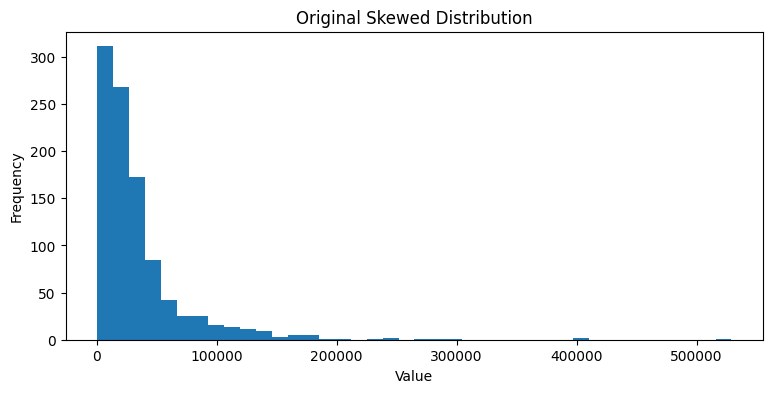

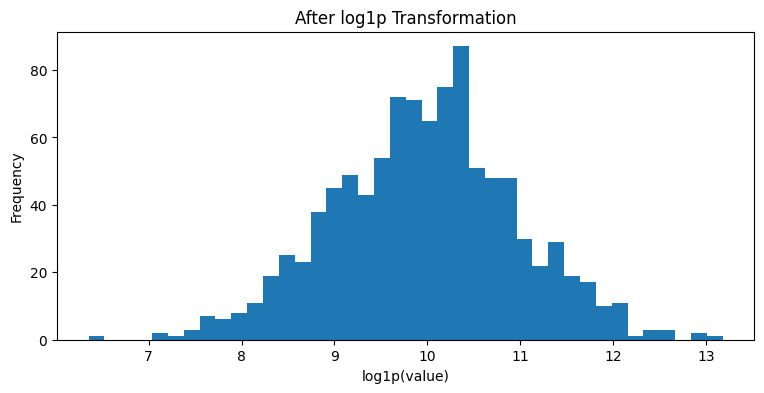

In [ ]:
# ============================================================
# TRANSFORMATION
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


# Create highly right-skewed data

skewed = rng.lognormal(

    mean=10,

    sigma=1.0,

    size=1000

)


# Log transformation

log_transformed = np.log1p(
    skewed
)


print(
    "Original skew:",
    round(
        pd.Series(skewed).skew(),
        2
    )
)


print(
    "Log-transformed skew:",
    round(
        pd.Series(log_transformed).skew(),
        2
    )
)


# Original distribution

plt.figure(
    figsize=(9, 4)
)

plt.hist(
    skewed,
    bins=40
)

plt.title(
    "Original Skewed Distribution"
)

plt.xlabel(
    "Value"
)

plt.ylabel(
    "Frequency"
)

plt.show()


# Transformed distribution

plt.figure(
    figsize=(9, 4)
)

plt.hist(
    log_transformed,
    bins=40
)

plt.title(
    "After log1p Transformation"
)

plt.xlabel(
    "log1p(value)"
)

plt.ylabel(
    "Frequency"
)

plt.show()

In [ ]:
# ============================================================
# NLP FEATURE ENGINEERING — TF-IDF
# ============================================================

texts = [

    "customer loves the fast internet",

    "customer reports slow internet",

    "customer loves fast service",

    "customer reports billing problem",

    "fast internet and excellent service",

    "slow internet and repeated support tickets"

]


# Create TF-IDF vectorizer

tfidf = TfidfVectorizer(
    stop_words="english"
)


# Transform text

X_text = tfidf.fit_transform(
    texts
)


# Convert to DataFrame

tfidf_table = pd.DataFrame(

    X_text.toarray(),

    columns=
        tfidf.get_feature_names_out()

)


display(
    tfidf_table.round(2)
)


print(
    "Number of generated features:",
    X_text.shape[1]
)

,billing,customer,excellent,fast,internet,loves,problem,repeated,reports,service,slow,support,tickets
0,0.00,0.44,0.00,0.51,0.44,0.60,0.00,0.0,0.00,0.00,0.00,0.0,0.0
1,0.00,0.41,0.00,0.00,0.41,0.00,0.00,0.0,0.57,0.00,0.57,0.0,0.0
2,0.00,0.40,0.00,0.47,0.00,0.56,0.00,0.0,0.00,0.56,0.00,0.0,0.0
3,0.58,0.34,0.00,0.00,0.00,0.00,0.58,0.0,0.47,0.00,0.00,0.0,0.0
4,0.00,0.00,0.63,0.44,0.37,0.00,0.00,0.0,0.00,0.52,0.00,0.0,0.0
5,0.00,0.00,0.00,0.00,0.30,0.00,0.00,0.5,0.00,0.00,0.41,0.5,0.5


Number of generated features: 13


,Polynomial degree,Training MSE,Test MSE
0,1,0.480,0.471
1,2,0.433,0.409
2,3,0.387,0.462
3,5,0.078,0.192
4,10,0.053,0.163
5,20,0.039,0.149


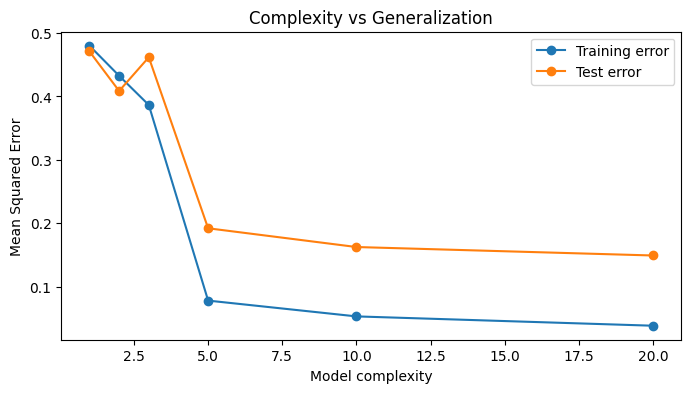

In [ ]:
# ============================================================
# FEATURE COMPLEXITY AND OVERFITTING
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


# Create noisy data

x = np.linspace(
    0,
    10,
    80
)


y_regression = (

    np.sin(x)

    +

    0.15 * x

    +

    rng.normal(
        0,
        0.35,
        len(x)
    )

)


# Train-test split

Xtr_reg, Xte_reg, ytr_reg, yte_reg = train_test_split(

    x.reshape(-1, 1),

    y_regression,

    test_size=0.30,

    random_state=RANDOM_STATE

)


degrees = [
    1,
    2,
    3,
    5,
    10,
    20
]


train_errors = []

test_errors = []


for degree in degrees:

    model = Pipeline([

        (
            "poly",
            PolynomialFeatures(
                degree=degree
            )
        ),

        (
            "scale",
            StandardScaler()
        ),

        (
            "linear",
            LinearRegression()
        )

    ])


    model.fit(
        Xtr_reg,
        ytr_reg
    )


    train_errors.append(

        mean_squared_error(

            ytr_reg,

            model.predict(Xtr_reg)

        )

    )


    test_errors.append(

        mean_squared_error(

            yte_reg,

            model.predict(Xte_reg)

        )

    )


# Results table

complexity = pd.DataFrame({

    "Polynomial degree":
        degrees,

    "Training MSE":
        train_errors,

    "Test MSE":
        test_errors

})


display(
    complexity.round(3)
)


# Plot

plt.figure(
    figsize=(8, 4)
)

plt.plot(

    degrees,

    train_errors,

    marker="o",

    label="Training error"

)


plt.plot(

    degrees,

    test_errors,

    marker="o",

    label="Test error"

)


plt.xlabel(
    "Model complexity"
)

plt.ylabel(
    "Mean Squared Error"
)

plt.title(
    "Complexity vs Generalization"
)

plt.legend()

plt.show()

In [ ]:
# ============================================================
# DATA LEAKAGE
# ============================================================

leak_demo = df[

    [
        "tenure",

        "monthly_charges",

        "contract",

        "support_tickets",

        "churn"
    ]

].copy()


# Create an artificial future-only feature

leak_demo["cancellation_date"] = pd.NaT

leak_demo.loc[
    leak_demo["churn"] == 1,
    "cancellation_date"
] = pd.Timestamp("2026-08-01")


display(
    leak_demo.head(10)
)


print(
    "SAFE:"
)

print(
    "Information available at the "
    "exact prediction time."
)


print(
    "\nLEAK:"
)

print(
    "Information created after the "
    "outcome or decision."
)


print(
    "\nExamples:"
)

print(
    "Cancellation date, post-outcome notes, "
    "refund information, or events caused by churn."
)

,tenure,monthly_charges,contract,support_tickets,churn,cancellation_date
0,7,106.20,One year,2,1,2026-08-01
1,56,68.69,Two year,0,1,2026-08-01
2,48,84.09,Month-to-month,2,1,2026-08-01
3,32,20.00,Two year,2,0,NaT
4,32,46.09,Month-to-month,2,1,2026-08-01
5,62,67.66,One year,1,0,NaT
6,7,48.20,One year,0,0,NaT
7,51,92.86,One year,1,0,NaT
8,15,124.93,Month-to-month,2,1,2026-08-01
9,7,45.58,One year,1,1,2026-08-01


SAFE:
Information available at the exact prediction time.

LEAK:
Information created after the outcome or decision.

Examples:
Cancellation date, post-outcome notes, refund information, or events caused by churn.


In [ ]:
# ============================================================
# END-TO-END MACHINE LEARNING PIPELINE
# ============================================================

pipeline_numeric = [
    "tenure",
    "monthly_charges",
    "total_charges",
    "support_tickets",
    "payment_delay_days",
    "ChargePressure",
    "HighChargePressure"
]

stratify=y_churn

pipeline_categorical = (

    categorical_features

)


# Preprocessing

pipeline_preprocessor = ColumnTransformer([

    (

        "num",

        Pipeline([

            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),

            (
                "scaler",
                StandardScaler()
            )

        ]),

        pipeline_numeric

    ),

    (

        "cat",

        Pipeline([

            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),

            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore"
                )
            )

        ]),

        pipeline_categorical

    )

])


# Complete pipeline

pipeline = Pipeline([

    (
        "preprocessing",
        pipeline_preprocessor
    ),

    (
        "model",
        LogisticRegression(
            max_iter=1000
        )
    )

])


# Data

X_pipeline = df[
    pipeline_numeric
    +
    pipeline_categorical
]


# Split

Xtr, Xte, ytr, yte = train_test_split(

    X_pipeline,

    y_churn,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y

)


# Train

pipeline.fit(
    Xtr,
    ytr
)


# Predict

pipeline_predictions = pipeline.predict(
    Xte
)


# Evaluate

pipeline_accuracy = accuracy_score(

    yte,

    pipeline_predictions

)


print(
    f"Pipeline test accuracy: "
    f"{pipeline_accuracy:.2%}"
)


print(
    "\nPipeline structure:"
)

print(
    pipeline
)

Pipeline test accuracy: 75.00%

Pipeline structure:
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'monthly_charges',
                                                   'total_charges',
                                                   'support_tickets',
                                                   'payment_delay_days',
                                                   'ChargePressure',
                                                   'HighChargePressure']),
                                                 ('cat',
                    

In [ ]:
# ============================================================
# FEATURE DIAGNOSTIC
# ============================================================
categorical_features = [
    "contract",
    "internet_service"
]
baseline_preprocessor = ColumnTransformer([
    (
        "num",
        numeric_pipe,
        baseline_numeric_features
    ),
    (
        "cat",
        categorical_pipe,
        categorical_features
    )
])
engineered_preprocessor = ColumnTransformer([
    (
        "num",
        numeric_pipe,
        engineered_numeric_features
    ),
    (
        "cat",
        categorical_pipe,
        categorical_features
    )
])

baseline_model = Pipeline([
    (
        "preprocess",
        baseline_preprocessor
    ),
    (
        "model",
        LogisticRegression(max_iter=1000)
    )
])

engineered_model = Pipeline([
    (
        "preprocess",
        engineered_preprocessor
    ),
    (
        "model",
        LogisticRegression(max_iter=1000)
    )
])


baseline_model.fit(
    X_train_b,
    y_train_b
)

engineered_model.fit(
    X_train_e,
    y_train_e
)

baseline_accuracy = accuracy_score(
    y_test_b,
    baseline_model.predict(X_test_b)
)

engineered_accuracy = accuracy_score(
    y_test_e,
    engineered_model.predict(X_test_e)
)

In [ ]:
# ============================================================
# FINAL SUMMARY
# ============================================================

summary = pd.DataFrame({

    "Stage": [

        "Raw data",

        "Baseline",

        "Feature engineering",

        "Engineered model",

        "Validation mindset"

    ],

    "Key lesson": [

        "Raw columns may hide useful relationships.",

        "Always establish a reference score.",

        "Ratios and transformations can expose behavior.",

        "Compare using the same evaluation setup.",

        "Reject leakage, noise, and weak features."

    ]

})


display(summary)


print()


,Stage,Key lesson
0,Raw data,Raw columns may hide useful relationships.
1,Baseline,Always establish a reference score.
2,Feature engineering,Ratios and transformations can expose behavior.
3,Engineered model,Compare using the same evaluation setup.
4,Validation mindset,"Reject leakage, noise, and weak features."


In [ ]:
# ============================================================
# FINAL VISUAL — BASELINE VS ENGINEERED
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Feature Engineered"
    ],
    "Accuracy": [
        baseline_accuracy,
        engineered_accuracy
    ]
})
display(
    comparison.style.format({
        "Accuracy": "{:.2%}"
    })
)
print(
    f"Accuracy improvement: "
    f"{(engineered_accuracy - baseline_accuracy):+.2%}"
)



,Model,Accuracy
0,Baseline,70.00%
1,Feature Engineered,75.00%


Accuracy improvement: +5.00%
